In [93]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

# Specify each path

In [94]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.hdf5'

# Set number of classes

In [95]:
NUM_CLASSES = 28

# Dataset reading

In [96]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [97]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [98]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# Model building

In [99]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [100]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dropout_8 (Dropout)         (None, 42)                0         
                                                                 
 dense_12 (Dense)            (None, 20)                860       
                                                                 
 dropout_9 (Dropout)         (None, 20)                0         
                                                                 
 dense_13 (Dense)            (None, 10)                210       
                                                                 
 dense_14 (Dense)            (None, 28)                308       
                                                                 
Total params: 1378 (5.38 KB)
Trainable params: 1378 (5.38 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [101]:
# Model checkpoint callback
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# Callback for early stopping
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [102]:
# Model compilation
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model training

In [103]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
1/8 [==>...........................] - ETA: 4s - loss: 3.4944 - accuracy: 0.0156
Epoch 1: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
8/8 [==============================] - 1s 78ms/step - loss: 3.4058 - accuracy: 0.0216 - val_loss: 3.3275 - val_accuracy: 0.0585
Epoch 2/1000
1/8 [==>...........................] - ETA: 0s - loss: 3.2882 - accuracy: 0.0391
Epoch 2: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
8/8 [==============================] - 0s 12ms/step - loss: 3.2628 - accuracy: 0.0391 - val_loss: 3.2127 - val_accuracy: 0.0892
Epoch 3/1000
1/8 [==>...........................] - ETA: 0s - loss: 3.2208 - accuracy: 0.0781
Epoch 3: saving model to model/keypoint_classifier\keypoint_classifier.hdf5


c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


8/8 [==============================] - 0s 15ms/step - loss: 3.1709 - accuracy: 0.0741 - val_loss: 3.0975 - val_accuracy: 0.0985
Epoch 4/1000
1/8 [==>...........................] - ETA: 0s - loss: 3.0635 - accuracy: 0.0625
Epoch 4: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
8/8 [==============================] - 0s 11ms/step - loss: 3.0318 - accuracy: 0.1049 - val_loss: 2.9652 - val_accuracy: 0.1108
Epoch 5/1000
1/8 [==>...........................] - ETA: 0s - loss: 2.9190 - accuracy: 0.2109
Epoch 5: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
8/8 [==============================] - 0s 13ms/step - loss: 2.8908 - accuracy: 0.1615 - val_loss: 2.8123 - val_accuracy: 0.1846
Epoch 6/1000
1/8 [==>...........................] - ETA: 0s - loss: 2.8054 - accuracy: 0.1328
Epoch 6: saving model to model/keypoint_classifier\keypoint_classifier.hdf5
8/8 [==============================] - 0s 11ms/step - loss: 2.7349 - accuracy: 0.2109 - val_loss: 2.6396 -

In [104]:
# Model evaluation
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

3/3 [==============================] - 0s 3ms/step - loss: 0.4959 - accuracy: 0.9015


In [105]:
# Loading the saved model

model = tf.keras.models.load_model(model_save_path)

In [106]:
# Inference test
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 [==============================] - 0s 52ms/step
[7.9898536e-02 1.2231445e-10 2.2479281e-09 2.2214605e-08 6.1761093e-01
 1.1783104e-09 1.1895096e-07 4.5058094e-12 1.2229493e-09 1.8761638e-08
 9.5608721e-13 5.1278301e-11 1.5958042e-07 7.8168505e-06 3.7100361e-15
 6.2826593e-09 8.2057836e-13 1.2177964e-08 3.0248237e-01 8.2018177e-11
 1.2882558e-11 2.2144812e-11 4.5955056e-11 2.7297430e-13 2.8637268e-13
 3.0211902e-11 1.8496633e-09 1.3340584e-08]
4


# Confusion matrix

11/11 [==============================] - 0s 1ms/step


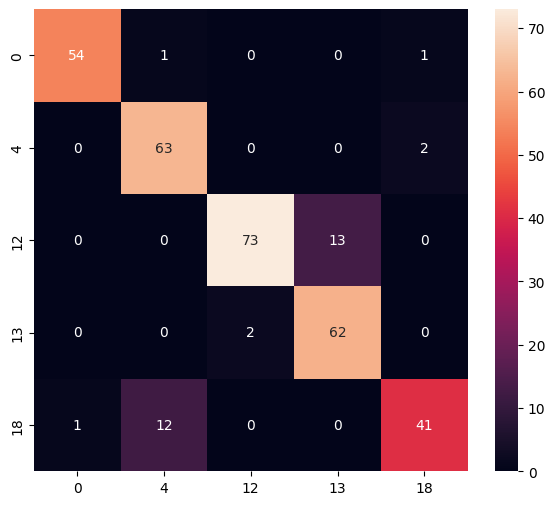

Classification Report
              precision    recall  f1-score   support

           0       0.98      0.96      0.97        56
           4       0.83      0.97      0.89        65
          12       0.97      0.85      0.91        86
          13       0.83      0.97      0.89        64
          18       0.93      0.76      0.84        54

    accuracy                           0.90       325
   macro avg       0.91      0.90      0.90       325
weighted avg       0.91      0.90      0.90       325



In [107]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Convert to model for Tensorflow-Lite

In [108]:
# Save as a model dedicated to inference
model.save(model_save_path, include_optimizer=False)

c:\Users\markl\anaconda3\envs\opencv_env\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [109]:
# Transform model (quantization)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpb0jgt1u3\assets


INFO:tensorflow:Assets written to: C:\Users\markl\AppData\Local\Temp\tmpb0jgt1u3\assets


7664

# Inference test

In [110]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

In [111]:
# Get I / O tensor
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [112]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [113]:
%%time
# Inference implementation
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 0 ns
Wall time: 0 ns


In [114]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[7.9898424e-02 1.2231462e-10 2.2479314e-09 2.2214635e-08 6.1761063e-01
 1.1783099e-09 1.1895101e-07 4.5058163e-12 1.2229485e-09 1.8761664e-08
 9.5608840e-13 5.1278273e-11 1.5958048e-07 7.8168459e-06 3.7100344e-15
 6.2826571e-09 8.2057803e-13 1.2177958e-08 3.0248278e-01 8.2018128e-11
 1.2882552e-11 2.2144800e-11 4.5955031e-11 2.7297470e-13 2.8637308e-13
 3.0211941e-11 1.8496659e-09 1.3340603e-08]
4
